# Lab 11B: Content and Collaborative Recommendation
**Course 961731 Business Data Analytics, Week 11**

Notebook นี้ทำตามโจทย์ Lab 11B ครบ Part 1.1 ถึง 3.3 โค้ดคำนวณจริงอยู่ใน `lab11B_content_cf.py` และใช้ contract เดียวกับ Lab 11A (`reco_contract.py`)

**ภาพรวมแบบง่าย:** มี 2 วิธีหลักในการแนะนำสินค้า
- **Content-based:** "คุณชอบกาแฟคั่ว ลองชิ้นนี้ที่คำอธิบายคล้ายกันดูไหม" ดูจาก **คำอธิบายสินค้า**
- **Collaborative Filtering (CF):** "คนที่ชอบเหมือนคุณ ชอบชิ้นนี้" ดูจาก **พฤติกรรมการให้คะแนน** ไม่ต้องรู้ว่าสินค้าคืออะไร

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
os.makedirs('figures', exist_ok=True); os.makedirs('evidence', exist_ok=True)
from IPython.display import Image, display
import reco_contract as rc
import lab11B_content_cf as lab
df = rc.load_events(); rc.validate_events(df)
train, valid, test = rc.temporal_split(df)
tiny_cat, wide, R_tiny = lab.load_tiny()
catalog = lab.load_catalog()
print(len(train), len(valid), len(test), len(catalog))

121 38 41 70


## Problem 1: Content-based Recommender

**1.1 TF-IDF แบบง่าย:** แปลงคำอธิบายสินค้าเป็นตัวเลข
- **TF** (term frequency) = log10(1 + จำนวนครั้งที่คำนั้นปรากฏ) คำที่ซ้ำบ่อยได้คะแนนเพิ่ม แต่เพิ่มแบบชะลอลง
- **IDF** (inverse document frequency) = log10(N / จำนวนสินค้าที่มีคำนั้น) คำที่มีในทุกสินค้า (เช่น "large") บอกอะไรได้น้อย จึงได้น้ำหนักต่ำ
- คูณกันแล้วทำให้เวกเตอร์ยาว 1 หน่วย (**L2-normalize**) เพื่อให้คำอธิบายสั้นหรือยาวเทียบกันได้

สูตรนี้เป็น **convention ของห้องเรียน** ไม่ใช่ค่า default ของ scikit-learn (ซึ่งใช้ raw count และ smoothed natural-log IDF) ตัวเลขจึงต่างกัน ต้องประกาศเสมอว่าใช้สูตรไหน

**1.2 Profile:** สร้าง "รสนิยม" ของลูกค้าจากสินค้าที่ชอบเท่านั้น น้ำหนัก = max(rating - 3, 0) ให้ 5 ดาว = 2, 4 ดาว = 1, 3 ดาวลงไป = 0

**1.3 Recommend:** วัดความคล้ายด้วย **cosine** (มุมระหว่างเวกเตอร์ ยิ่งชี้ทางเดียวกันยิ่งคล้าย) แล้วตัดของที่ซื้อแล้วออก


PROBLEM 1.1  CLASSROOM TF-IDF REPRESENTATION
Synthetic catalog: 70 items; provenance labels = ['SYNTHETIC_TEACHING_ONLY']
Descriptions are teaching data, not real product text.

Tiny catalog term counts:
        coffee  herbal  roast  tea
ItemID                            
A            2       0      1    0
B            1       0      2    0
C            0       1      0    2
D            1       1      0    1

Document frequency and IDF = log10(N/df), N = 4:
        df       idf
coffee   3  0.124939
herbal   2  0.301030
roast    2  0.301030
tea      2  0.301030

Count-two cell (A, coffee): TF = log10(1+2) = 0.477121; TF-IDF = 0.477121 x 0.124939 = 0.059611
Norm of A = 0.108468; normalised A = [0.549572, 0.0, 0.835446, 0.0]
Library default (scikit-learn TfidfVectorizer): raw TF 2, smoothed IDF ln(5/4)+1 = 1.223144, cell before L2 = 2.446287 -> different numbers, so the convention must be declared.

Real synthetic catalog: 70 items x 10 terms
         df       idf
large    36  0.288796

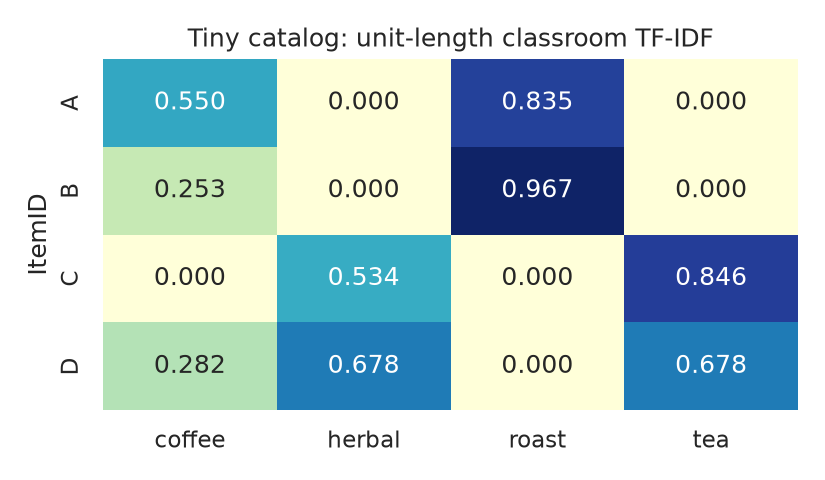

In [2]:
unit, real_unit, popularity, warm = lab.problem1(tiny_cat, catalog, train)
display(Image('figures/tiny_tfidf.png'))

## Problem 2: Neighborhood Models (CF)

**2.1 User-based CF:** หา "เพื่อนรสนิยมเดียวกัน" ด้วย **Pearson correlation** ซึ่งดูว่าสองคนให้คะแนน **ขึ้นลงไปทางเดียวกัน** ไหม (ไม่สนว่าคนหนึ่งใจดีให้คะแนนสูงกว่า)
- ต้องมีสินค้าที่ให้คะแนนร่วมกันอย่างน้อย 3 ชิ้น (**min overlap**)
- **Shrinkage** n/(n+2): เห็นด้วยกันแค่ 3 ชิ้นยังไม่น่าเชื่อเท่าเห็นด้วยกัน 30 ชิ้น จึงลดน้ำหนักลง
- ใช้เพื่อนที่ similarity เป็นบวก 2 คนที่ดีที่สุด

**2.2 Item-based CF:** หา "สินค้าที่คนให้คะแนนคล้ายกัน" ด้วย **adjusted cosine** ซึ่งลบค่าเฉลี่ยของแต่ละคนก่อน เพื่อตัดนิสัย "คนใจดี/คนใจร้าย" ออก

**2.3 Verify:** คำนวณด้วยมือเทียบกับโค้ด และทดสอบกรณีที่คำนวณไม่ได้ (คะแนนเท่ากันทุกชิ้น)

In [3]:
traces = lab.problem2(wide, R_tiny)
traces


PROBLEM 2.1  USER-USER PEARSON WITH OVERLAP SHRINKAGE
Rating matrix (NaN = unknown):
          A    B    C    D
UserID                    
U0      5.0  3.0  4.0    ?
U1      4.0  2.0  4.0  5.0
U2      1.0  5.0  1.0  2.0
U3      5.0  3.0  4.0  4.0
U4      2.0  4.0  2.0  3.0

Observation mask:
        A  B  C  D
UserID            
U0      1  1  1  0
U1      1  1  1  1
U2      1  1  1  1
U3      1  1  1  1
U4      1  1  1  1

Full observed row means: {'U0': 4.0, 'U1': 3.75, 'U2': 2.25, 'U3': 4.0, 'U4': 2.75}

Candidates who rated D (target U0, min overlap 3, weight = r x n/(n+2)):
neighbor  overlap   pearson  shrunk_weight  used
      U1        3  0.866025       0.519615  True
      U2        3 -0.866025      -0.519615 False
      U3        3  1.000000       0.600000  True
      U4        3 -0.866025      -0.519615 False


Pair centring: Pearson subtracts each user's mean over the CO-RATED items only (fair comparison).
Prediction centring: residuals use each neighbour's FULL row mean (their usual rating level).

PROBLEM 2.2  ITEM-ITEM ADJUSTED COSINE
pair  support  adj_cosine  shrunk_weight  selected
 D-A        4    0.188639       0.125759      True
 D-B        4   -0.543201      -0.362134     False
 D-C        4    0.227710       0.151807      True
Adjusted cosine compares how USERS rate two items (behaviour, centred per user);
text cosine compares words in two descriptions. Same formula shape, different evidence.

PROBLEM 2.3  VERIFY PREDICTIONS AND A BOUNDARY CASE
User-CF by hand: 4 + [0.6(4-4) + 0.519615(5-3.75)] / (0.6 + 0.519615) = 4.580127
User-CF by code: 4.580127 (user_cf)
Item-CF by hand: 4 + [0.188639(5-4) + 0.227710(4-4)] / (0.188639 + 0.227710) = 4.453079 (unrounded weights)
Item-CF by code: 4.453079 (item_cf); the 4/6 shrinkage cancels because both supports are 4
Boundary: U0 rates A,B,C a

{'user_cf_U0_D': 4.580127018922194,
 'item_cf_U0_D': 4.453078771784701,
 'constant_rating_fallback': 3.0}

## Problem 3: เปรียบเทียบ 4 วิธีบนข้อมูลจริง

ใช้กติกาเดียวกับ Lab 11A ทุกอย่าง: split เดิม, catalog 70 ชิ้น, K = 5, relevant = rating >= 4

**ข้อควรรู้:** ข้อมูลจริงบางมาก (แต่ละ user ให้คะแนน 1 ถึง 4 ชิ้น) แทบไม่มีคู่ไหนให้คะแนนสินค้าร่วมกันถึง 3 ชิ้น CF จึงต้อง fallback ไปใช้ค่าเฉลี่ยของ user เกือบทั้งหมด การ fallback อย่างซื่อสัตย์ดีกว่าการเติม 0 ลงในช่องว่าง


PROBLEM 3.1  SAME WARM USER, FOUR METHODS
Warm user 2; training ratings {'516': 4.0, '552': 3.0, '508': 5.0, '540': 1.0}
popularity: ['524', '546', '556', '557', '588']  [training popularity, seen items removed]
content   : ['538', '598', '553', '503', '533']  [content]
user_cf   : ['524', '546', '556', '557', '588']  [score sources {'user_mean(no positive neighbor)': 5}]
item_cf   : ['524', '546', '556', '557', '588']  [score sources {'user_mean(no positive item neighbor)': 5}]
CF lists equal the popularity order here because every candidate fell back to the user's mean:
the largest overlap between any two training users is 2 items, below MIN_OVERLAP = 3.

PROBLEM 3.2  FAIR EVALUATION UNDER THE LAB 11A CONTRACT
split     method  users  cold_users  precision@5  recall@5  ndcg@5  coverage  fallback_share
valid popularity     10           6         0.04       0.2  0.0931    0.0857          1.0000
valid    content     10           6         0.04       0.2  0.0931    0.2143          0.800


PROBLEM 3.3  STRESS TESTS ON SEPARATE COPIES
missing metadata (B)  : B vector all zero, score 0.0; D 0.6769 -> finite, B ranks by tie-break
zero text vector (A)  : A='coffee' with coffee in all 4 docs (IDF 0) -> norm 0, profile None -> popularity fallback
constant ratings (U0) : Pearson undefined -> 3.0000 via user_mean(no positive neighbor)
no overlap (U9)       : user-CF 4.0000 via user_mean(no positive neighbor); item-CF 4.0000 via user_mean(no positive item neighbor)
interpretation        : each case is missing data support, not an arithmetic error: no NaN, no division by zero


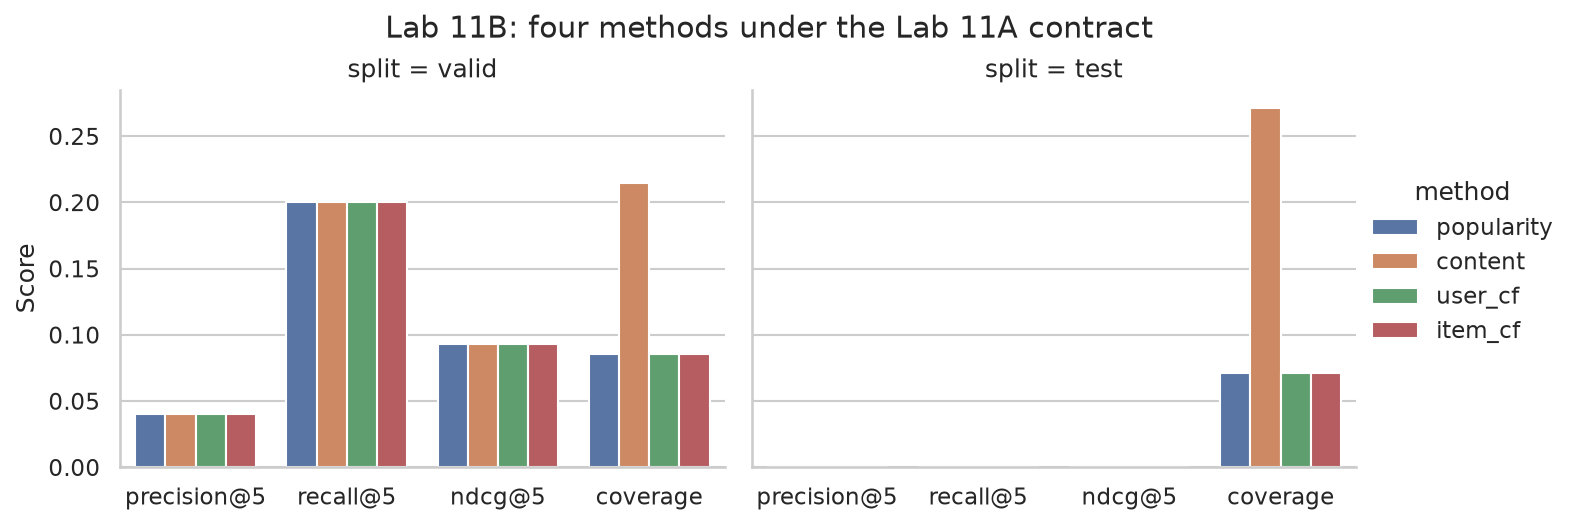

,split,method,users,cold_users,precision@5,recall@5,ndcg@5,coverage,fallback_share
0,valid,popularity,10,6,0.04,0.2,0.0931,0.0857,1.0000
1,valid,content,10,6,0.04,0.2,0.0931,0.2143,0.8000
2,valid,user_cf,10,6,0.04,0.2,0.0931,0.0857,1.0000
3,valid,item_cf,10,6,0.04,0.2,0.0931,0.0857,1.0000
4,test,popularity,9,2,0.00,0.0,0.0000,0.0714,1.0000
5,test,content,9,2,0.00,0.0,0.0000,0.2714,0.5556
6,test,user_cf,9,2,0.00,0.0,0.0000,0.0714,1.0000
7,test,item_cf,9,2,0.00,0.0,0.0000,0.0714,1.0000


In [4]:
table, lists, stress = lab.problem3(train, valid, test, real_unit, popularity, warm, rc.K)
display(Image('figures/method_comparison.png'))
table.round(4)